# Analyses added during peer review

Run after notebooks 01 and 04 (Model J). None of these cells retrains NMS-XGB.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Exact reproduction requires XGBoost 3.3.0 (restart the runtime after installing)
!pip install -q xgboost==3.3.0

## DD group characterization and subgroup performance (Reviewer 1, comments 1 and 4)

R1-Q1 — DD GROUP CHARACTERIZATION
Patient JSON files parsed : 469
Available metadata fields : ['age', 'age_at_diagnosis', 'appearance_in_first_grade_kinship', 'appearance_in_kinship', 'condition', 'disease_comment', 'effect_of_alcohol_on_tremor', 'gender', 'handedness', 'height', 'id', 'resource_type', 'study_id', 'weight']

Raw values of 'appearance_in_kinship':
appearance_in_kinship
False    343
True     126

Raw values of 'appearance_in_first_grade_kinship':
appearance_in_first_grade_kinship
None     288
False     91
True      90

Raw values of 'effect_of_alcohol_on_tremor':
effect_of_alcohol_on_tremor
Unknown        228
No effect      181
Improvement     34
Worsening       26
Label consistency (condition vs true_label): OK

TABLE A — DD COMPOSITION
            dd_diagnosis  participants  percent_of_dd  percent_of_cohort
        Essential Tremor            28           24.6                7.2
   Atypical Parkinsonism            15           13.2                3.8
      Multiple Scl

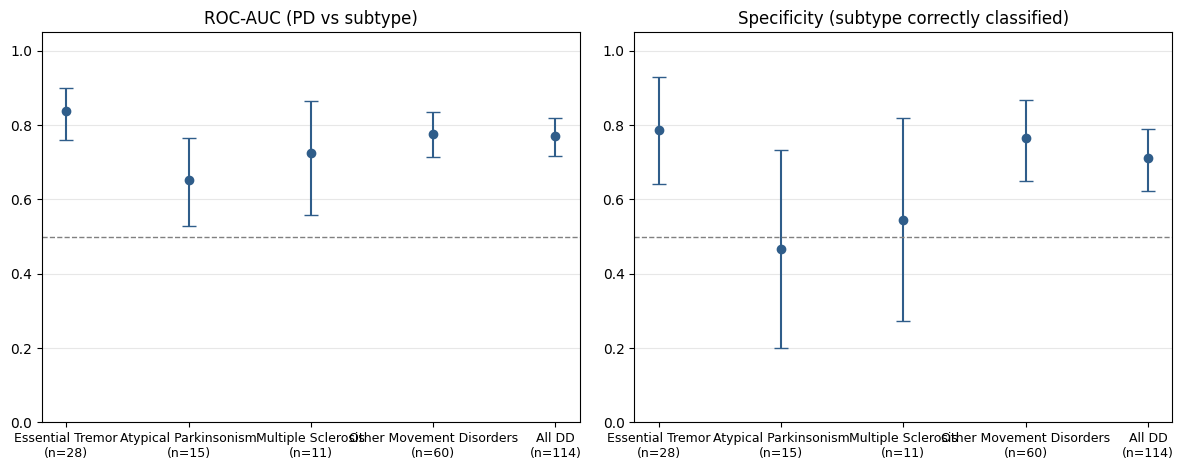

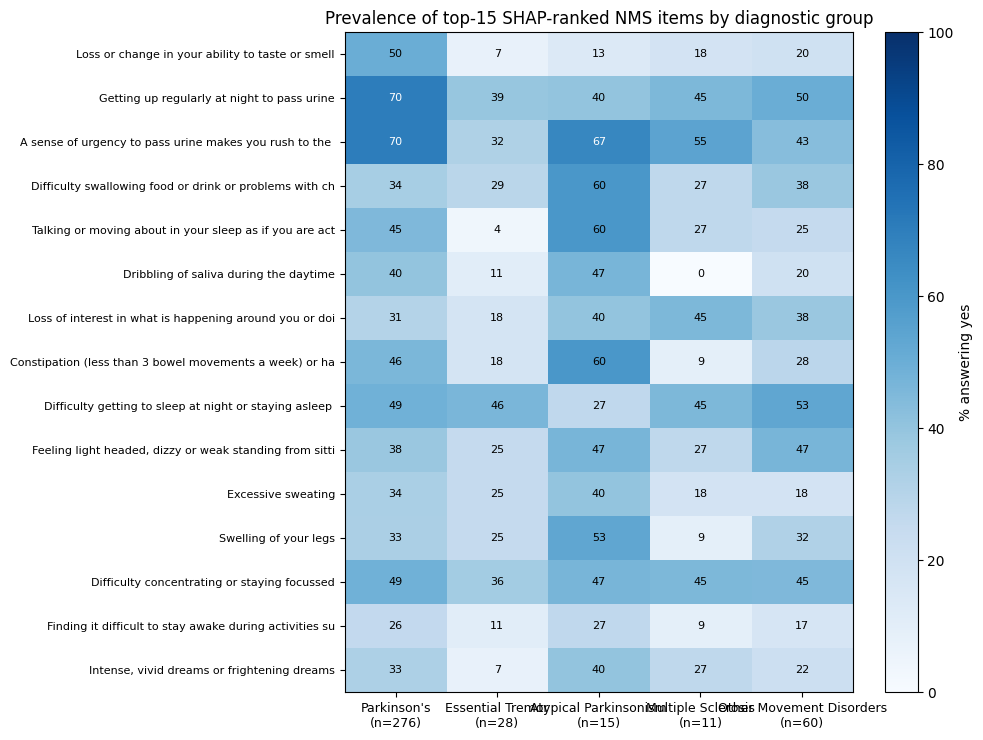

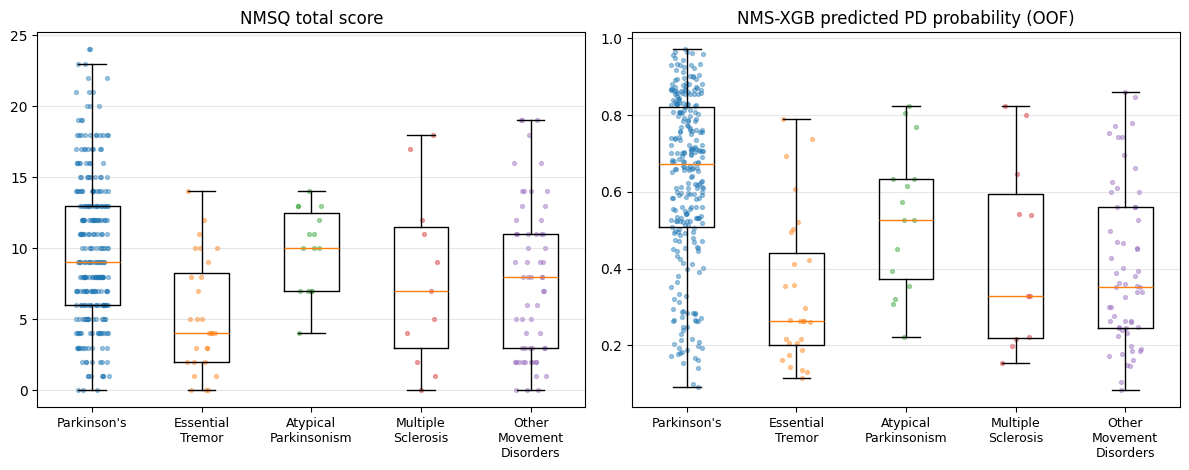


Saved to: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/revision_R1Q1_dd_characterization
 - TableA2_dd_disease_comment_breakdown.csv
 - TableA_dd_subtype_composition.csv
 - TableB_clinical_characteristics_by_group.csv
 - TableC_manuscript_ready.csv
 - TableC_pd_vs_each_subtype_performance.csv
 - TableD_nms_item_prevalence_by_group.csv
 - TableE_mean_signed_shap_by_group.csv
 - analytical_cohort_with_predictions.csv
 - figures/FigR1_pd_vs_subtype_performance.pdf
 - figures/FigR1_pd_vs_subtype_performance.png
 - figures/FigR2_nms_prevalence_heatmap.pdf
 - figures/FigR2_nms_prevalence_heatmap.png
 - figures/FigR3_score_and_probability_by_group.pdf
 - figures/FigR3_score_and_probability_by_group.png
✅ R1-Q1 DD CHARACTERIZATION FINISHED (no model was retrained).


In [ ]:
# ==================================================================================================
# REVISION — REVIEWER 1, COMMENT 1 (+ supports R1-Q4 and Reviewer 2)
# DIFFERENTIAL-DIAGNOSIS (DD) GROUP CHARACTERIZATION AND PD-vs-SUBTYPE PERFORMANCE
#
# This cell DOES NOT retrain any model.
#
# Uses:
#   1. PADS patient JSON files (patients/*.json)        -> diagnosis, disease_comment, demographics
#   2. pads_complete_data.npz (from EX cell 1)          -> 30 NMS item responses
#   3. model_j_patient_predictions.csv (Model J)        -> untouched OOF NMS-XGB predictions
#   4. model_j_patient_level_shap_values.csv (optional) -> outer-test SHAP values
#
# Outputs (project_ready_data/revision_R1Q1_dd_characterization/):
#   Table A  dd_subtype_composition.csv          individual diagnoses, n, %
#   Table A2 dd_disease_comment_breakdown.csv    free-text diagnoses inside each DD category
#   Table B  clinical_characteristics_by_group.csv  age, sex, handedness, BMI, age at diagnosis,
#                                                   disease duration, family history, alcohol effect,
#                                                   NMSQ total score; with group-comparison p-values
#   Table C  pd_vs_each_subtype_performance.csv  ROC-AUC, specificity, BA (bootstrap 95% CI)
#   Table D  nms_item_prevalence_by_group.csv    % "yes" per item per group + PD-vs-subtype
#                                                Fisher tests (BH-FDR corrected)
#   Table E  shap_by_group.csv (if SHAP file found)
#   Figures  subtype performance, prevalence heatmap, NMSQ total score boxplot
# ==================================================================================================

import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

warnings.filterwarnings("ignore")

GLOBAL_SEED = 42
N_BOOTSTRAPS = 2000
PRIMARY_CONFIGURATION = "nms_items_only"

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)
PROJECT_DIR = BASE_DIR / "project_ready_data"

OUTPUT_DIR = PROJECT_DIR / "revision_R1Q1_dd_characterization"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DD_SUBTYPES = [
    "Essential Tremor",
    "Atypical Parkinsonism",
    "Multiple Sclerosis",
    "Other Movement Disorders",
]
GROUP_ORDER = ["Parkinson's"] + DD_SUBTYPES


# --------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------
def locate_file(filename, preferred=None):
    if preferred is not None and Path(preferred).exists():
        return Path(preferred)
    matches = sorted(BASE_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Required file not found under {BASE_DIR}: {filename}")
    return matches[0]


def normalize_ids(series):
    return (
        pd.Series(series)
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.extract(r"(\d+)", expand=False)
        .str.zfill(3)
    )


def to_number(value):
    try:
        if value is None or value == "":
            return np.nan
        return float(value)
    except Exception:
        return np.nan


def yes_no_to_number(value):
    if isinstance(value, bool):
        return float(value)
    if value is None:
        return np.nan
    text = str(value).strip().lower()
    if text in {"true", "yes", "1", "positive"} or "improv" in text or "better" in text:
        return 1.0
    if text in {"false", "no", "0", "negative"} or "no effect" in text or "worse" in text:
        return 0.0
    return np.nan  # "unknown", empty, etc.


def median_iqr(values):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if len(values) == 0:
        return "–"
    return (
        f"{values.median():.1f} "
        f"[{values.quantile(0.25):.1f}–{values.quantile(0.75):.1f}]"
    )


def mean_sd(values):
    values = pd.to_numeric(values, errors="coerce").dropna()
    if len(values) == 0:
        return "–"
    return f"{values.mean():.1f} ± {values.std(ddof=1):.1f}"


def n_percent(mask_values):
    mask_values = pd.Series(mask_values).dropna()
    if len(mask_values) == 0:
        return "–"
    count = int(mask_values.sum())
    return f"{count} ({100 * count / len(mask_values):.1f}%)"


def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full_like(p_values, np.nan)
    valid = np.isfinite(p_values)
    p = p_values[valid]
    if len(p) == 0:
        return adjusted
    order = np.argsort(p)
    ranked = p[order] * len(p) / (np.arange(len(p)) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    result = np.empty_like(p)
    result[order] = np.minimum(ranked, 1.0)
    adjusted[valid] = result
    return adjusted


def format_p(p):
    if not np.isfinite(p):
        return "–"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


print("=" * 110)
print("R1-Q1 — DD GROUP CHARACTERIZATION")
print("=" * 110)

# ==================================================================================================
# 1. PATIENT METADATA DIRECTLY FROM PADS JSON FILES
# ==================================================================================================
patient_json_files = sorted(
    path
    for path in BASE_DIR.rglob("*.json")
    if "patient" in path.name.lower() and "questionnaire" not in path.name.lower()
)

if not patient_json_files:
    raise FileNotFoundError("No PADS patient JSON files were found (expected patients/patient_XXX.json).")

metadata_rows = []
all_keys = set()
for path in patient_json_files:
    try:
        record = json.loads(path.read_text(encoding="utf-8"))
    except Exception as error:
        print("Could not parse", path.name, "|", str(error)[:120])
        continue
    if isinstance(record, list):
        record = record[0] if record else {}
    if not isinstance(record, dict) or "condition" not in record:
        continue
    all_keys.update(record.keys())
    record = dict(record)
    record["patient_id"] = record.get("id", path.stem)
    metadata_rows.append(record)

metadata = pd.DataFrame(metadata_rows)
metadata["patient_id"] = normalize_ids(metadata["patient_id"])
metadata = metadata.drop_duplicates("patient_id", keep="last").set_index("patient_id")
metadata["condition"] = metadata["condition"].astype(str).str.strip()

print("Patient JSON files parsed :", len(metadata))
print("Available metadata fields :", sorted(all_keys))

for column in ["age", "age_at_diagnosis", "height", "weight"]:
    if column in metadata.columns:
        metadata[column] = metadata[column].apply(to_number)

if {"height", "weight"}.issubset(metadata.columns):
    metadata["bmi"] = metadata["weight"] / (metadata["height"] / 100) ** 2
    metadata.loc[~np.isfinite(metadata["bmi"]) | (metadata["bmi"] <= 0), "bmi"] = np.nan

if {"age", "age_at_diagnosis"}.issubset(metadata.columns):
    metadata["disease_duration_years"] = metadata["age"] - metadata["age_at_diagnosis"]
    metadata.loc[metadata["disease_duration_years"] < 0, "disease_duration_years"] = np.nan

for column in [
    "appearance_in_kinship",
    "appearance_in_first_grade_kinship",
    "effect_of_alcohol_on_tremor",
]:
    if column in metadata.columns:
        print(f"\nRaw values of '{column}':")
        print(metadata[column].astype(str).value_counts(dropna=False).to_string())
        metadata[column + "_num"] = metadata[column].apply(yes_no_to_number)

# ==================================================================================================
# 2. NMS ITEMS (30 questionnaire responses)
# ==================================================================================================
npz_file = locate_file(
    "pads_complete_data.npz",
    PROJECT_DIR / "pads_complete_data.npz",
)
npz = np.load(npz_file, allow_pickle=True)
nms_matrix = np.asarray(npz["X_questionnaire"], dtype=float)
nms_ids = normalize_ids(npz["patient_ids"]).to_numpy()
NMS_COLUMNS = [f"nms_{index:02d}" for index in range(1, nms_matrix.shape[1] + 1)]
nms_df = pd.DataFrame(nms_matrix, columns=NMS_COLUMNS, index=nms_ids)
nms_df = nms_df[~nms_df.index.duplicated(keep="last")]

question_text = {}
try:
    mapping_file = locate_file("model_j_nms_question_mapping.csv")
    mapping_df = pd.read_csv(mapping_file)
    if {"feature", "question_text"}.issubset(mapping_df.columns):
        question_text = (
            mapping_df.dropna(subset=["question_text"])
            .drop_duplicates("feature")
            .set_index("feature")["question_text"]
            .to_dict()
        )
except FileNotFoundError:
    print("Question mapping not found — item codes will be used as labels.")

# ==================================================================================================
# 3. PRIMARY NMS-XGB OUT-OF-FOLD PREDICTIONS (Model J)
# ==================================================================================================
prediction_file = locate_file("model_j_patient_predictions.csv")
prediction_df = pd.read_csv(prediction_file)
if "configuration" in prediction_df.columns:
    prediction_df = prediction_df[
        prediction_df["configuration"].astype(str).str.strip().str.lower()
        == PRIMARY_CONFIGURATION
    ]
prediction_df["patient_id"] = normalize_ids(prediction_df["patient_id"])
prediction_df = prediction_df.drop_duplicates("patient_id", keep="last").set_index("patient_id")

probability_column = next(
    c for c in ["predicted_probability_pd", "probability", "predicted_probability"]
    if c in prediction_df.columns
)
label_column = next(c for c in ["predicted_label", "prediction"] if c in prediction_df.columns)

if len(prediction_df) != 390:
    raise RuntimeError(f"Expected 390 primary predictions, found {len(prediction_df)}.")

# ==================================================================================================
# 4. MERGE ANALYTICAL COHORT (PD + DD = 390)
# ==================================================================================================
cohort = (
    prediction_df[["true_label", probability_column, label_column]]
    .rename(columns={probability_column: "probability_pd", label_column: "predicted_label"})
    .join(metadata, how="left")
    .join(nms_df, how="left")
)

missing_metadata = cohort["condition"].isna().sum()
if missing_metadata:
    raise RuntimeError(f"{missing_metadata} predicted patients have no metadata match — check ID formats.")

cohort["group"] = cohort["condition"]
unexpected = set(cohort["group"]) - set(GROUP_ORDER)
if unexpected:
    print("WARNING — unexpected condition labels in cohort:", unexpected)

label_check = (
    (cohort["group"] == "Parkinson's").astype(int) == cohort["true_label"].astype(int)
).all()
print("Label consistency (condition vs true_label):", "OK" if label_check else "MISMATCH")
if not label_check:
    raise RuntimeError("Condition labels do not match Model-J true labels.")

cohort["nmsq_total_score"] = cohort[NMS_COLUMNS].sum(axis=1, min_count=1)
cohort.to_csv(OUTPUT_DIR / "analytical_cohort_with_predictions.csv")

# ==================================================================================================
# TABLE A — DD COMPOSITION
# ==================================================================================================
print("\n" + "=" * 110)
print("TABLE A — DD COMPOSITION")
print("=" * 110)

dd_cohort = cohort[cohort["group"] != "Parkinson's"]
composition = (
    dd_cohort["group"].value_counts()
    .reindex(DD_SUBTYPES).fillna(0).astype(int)
    .rename_axis("dd_diagnosis").reset_index(name="participants")
)
composition["percent_of_dd"] = 100 * composition["participants"] / composition["participants"].sum()
composition["percent_of_cohort"] = 100 * composition["participants"] / len(cohort)
composition.to_csv(OUTPUT_DIR / "TableA_dd_subtype_composition.csv", index=False)
print(composition.to_string(index=False, float_format="%.1f"))

# Free-text diagnoses inside each category (this is where specific diagnoses are listed)
if "disease_comment" in cohort.columns:
    comment_breakdown = (
        cohort.assign(
            disease_comment=cohort["disease_comment"].astype(str).str.strip().replace(
                {"": "not specified", "nan": "not specified", "None": "not specified"}
            )
        )
        .groupby(["group", "disease_comment"]).size()
        .rename("participants").reset_index()
        .sort_values(["group", "participants"], ascending=[True, False])
    )
    comment_breakdown.to_csv(OUTPUT_DIR / "TableA2_dd_disease_comment_breakdown.csv", index=False)
    print("\nFree-text 'disease_comment' within each DD category (review manually and group into "
          "clinical diagnoses, e.g. dystonia, drug-induced parkinsonism, MSA, PSP ...):")
    for group_name in DD_SUBTYPES:
        subset = comment_breakdown[comment_breakdown["group"] == group_name]
        print(f"\n--- {group_name} ({subset['participants'].sum()}) ---")
        print(subset[["disease_comment", "participants"]].to_string(index=False))

# ==================================================================================================
# TABLE B — CLINICAL CHARACTERISTICS BY GROUP
# ==================================================================================================
print("\n" + "=" * 110)
print("TABLE B — CLINICAL CHARACTERISTICS")
print("=" * 110)

group_columns = GROUP_ORDER + ["All DD"]


def group_subset(name):
    if name == "All DD":
        return cohort[cohort["group"] != "Parkinson's"]
    return cohort[cohort["group"] == name]


def compare_continuous(column):
    """Kruskal–Wallis across 5 groups + Mann–Whitney PD vs all DD."""
    samples = [
        pd.to_numeric(group_subset(g)[column], errors="coerce").dropna()
        for g in GROUP_ORDER
    ]
    samples = [s for s in samples if len(s) > 0]
    p_kw = stats.kruskal(*samples).pvalue if len(samples) > 1 else np.nan
    pd_values = pd.to_numeric(group_subset("Parkinson's")[column], errors="coerce").dropna()
    dd_values = pd.to_numeric(group_subset("All DD")[column], errors="coerce").dropna()
    p_mw = (
        stats.mannwhitneyu(pd_values, dd_values).pvalue
        if len(pd_values) and len(dd_values) else np.nan
    )
    return p_kw, p_mw


def compare_binary(column):
    table = pd.crosstab(cohort["group"], cohort[column]).reindex(GROUP_ORDER).dropna()
    p_chi = (
        stats.chi2_contingency(table).pvalue
        if table.shape[0] > 1 and table.shape[1] > 1 else np.nan
    )
    binary = cohort.assign(_is_pd=cohort["group"] == "Parkinson's")
    table2 = pd.crosstab(binary["_is_pd"], binary[column])
    p_pd_dd = (
        stats.fisher_exact(table2.to_numpy()).pvalue
        if table2.shape == (2, 2) else
        (stats.chi2_contingency(table2).pvalue if table2.shape[1] > 1 else np.nan)
    )
    return p_chi, p_pd_dd


rows = []
rows.append({"Characteristic": "n", **{g: str(len(group_subset(g))) for g in group_columns},
             "p (5 groups)": "", "p (PD vs all DD)": ""})

continuous_variables = [
    ("age", "Age, years"),
    ("age_at_diagnosis", "Age at diagnosis, years"),
    ("disease_duration_years", "Disease duration, years"),
    ("bmi", "BMI, kg/m²"),
    ("nmsq_total_score", "NMSQ total score (0–30)"),
]
for column, label in continuous_variables:
    if column not in cohort.columns:
        continue
    p_kw, p_mw = compare_continuous(column)
    rows.append({
        "Characteristic": label + " — median [IQR]",
        **{g: median_iqr(group_subset(g)[column]) for g in group_columns},
        "p (5 groups)": format_p(p_kw), "p (PD vs all DD)": format_p(p_mw),
    })
    rows.append({
        "Characteristic": label + " — mean ± SD",
        **{g: mean_sd(group_subset(g)[column]) for g in group_columns},
        "p (5 groups)": "", "p (PD vs all DD)": "",
    })

if "gender" in cohort.columns:
    cohort["is_female"] = cohort["gender"].astype(str).str.lower().str.startswith("f").astype(float)
    p_chi, p_pd_dd = compare_binary("is_female")
    rows.append({"Characteristic": "Female, n (%)",
                 **{g: n_percent(group_subset(g)["is_female"]) for g in group_columns},
                 "p (5 groups)": format_p(p_chi), "p (PD vs all DD)": format_p(p_pd_dd)})

if "handedness" in cohort.columns:
    cohort["is_left_handed"] = cohort["handedness"].astype(str).str.lower().str.startswith("l").astype(float)
    p_chi, p_pd_dd = compare_binary("is_left_handed")
    rows.append({"Characteristic": "Left-handed, n (%)",
                 **{g: n_percent(group_subset(g)["is_left_handed"]) for g in group_columns},
                 "p (5 groups)": format_p(p_chi), "p (PD vs all DD)": format_p(p_pd_dd)})

for column, label in [
    ("appearance_in_kinship_num", "Family history (any relative), n (%)"),
    ("appearance_in_first_grade_kinship_num", "Family history (first-degree), n (%)"),
    ("effect_of_alcohol_on_tremor_num", "Tremor improves with alcohol, n (%)"),
]:
    if column in cohort.columns and cohort[column].notna().any():
        p_chi, p_pd_dd = compare_binary(column)
        rows.append({
            "Characteristic": label + f"  [missing: {int(cohort[column].isna().sum())}]",
            **{g: n_percent(group_subset(g)[column]) for g in group_columns},
            "p (5 groups)": format_p(p_chi), "p (PD vs all DD)": format_p(p_pd_dd),
        })

characteristics = pd.DataFrame(rows)
characteristics.to_csv(OUTPUT_DIR / "TableB_clinical_characteristics_by_group.csv", index=False)
print(characteristics.to_string(index=False))

print("\nNOTE: PADS does not provide UPDRS/H&Y severity, MoCA/cognition or medication status.\n"
      "These must be reported as a dataset limitation (relevant to R1-Q2).")

# ==================================================================================================
# TABLE C — PD vs EACH DD SUBTYPE (same untouched OOF predictions, no retraining)
# ==================================================================================================
print("\n" + "=" * 110)
print("TABLE C — PRIMARY NMS-XGB PERFORMANCE: PD vs EACH DD SUBTYPE")
print("=" * 110)

rng = np.random.default_rng(GLOBAL_SEED)


def subset_metrics(y_true, y_pred, y_prob):
    pd_mask = y_true == 1
    dd_mask = y_true == 0
    sensitivity = np.mean(y_pred[pd_mask] == 1) if pd_mask.any() else np.nan
    specificity = np.mean(y_pred[dd_mask] == 0) if dd_mask.any() else np.nan
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    return {
        "roc_auc": auc,
        "specificity_subtype": specificity,
        "sensitivity_pd": sensitivity,
        "balanced_accuracy": np.nanmean([sensitivity, specificity]),
        "dd_misclassified_as_pd": int(np.sum(y_pred[dd_mask] == 1)),
    }


def stratified_bootstrap(y_true, y_pred, y_prob):
    pd_index = np.where(y_true == 1)[0]
    dd_index = np.where(y_true == 0)[0]
    results = []
    for _ in range(N_BOOTSTRAPS):
        sample = np.concatenate([
            rng.choice(pd_index, size=len(pd_index), replace=True),
            rng.choice(dd_index, size=len(dd_index), replace=True),
        ])
        results.append(subset_metrics(y_true[sample], y_pred[sample], y_prob[sample]))
    return pd.DataFrame(results)


performance_rows = []
comparison_groups = DD_SUBTYPES + ["All DD"]
for subtype in comparison_groups:
    if subtype == "All DD":
        mask = np.ones(len(cohort), dtype=bool)
    else:
        mask = cohort["group"].isin(["Parkinson's", subtype]).to_numpy()
    y_true = cohort.loc[mask, "true_label"].astype(int).to_numpy()
    y_pred = cohort.loc[mask, "predicted_label"].astype(int).to_numpy()
    y_prob = cohort.loc[mask, "probability_pd"].astype(float).to_numpy()

    point = subset_metrics(y_true, y_pred, y_prob)
    boot = stratified_bootstrap(y_true, y_pred, y_prob)

    row = {"comparison": f"PD vs {subtype}", "n_pd": int((y_true == 1).sum()),
           "n_subtype": int((y_true == 0).sum())}
    for metric in ["roc_auc", "specificity_subtype", "balanced_accuracy"]:
        row[metric] = point[metric]
        row[metric + "_ci_lower"] = boot[metric].quantile(0.025)
        row[metric + "_ci_upper"] = boot[metric].quantile(0.975)
    row["subtype_misclassified_as_pd"] = point["dd_misclassified_as_pd"]
    row["mean_probability_pd_in_subtype"] = float(np.mean(y_prob[y_true == 0]))
    row["small_sample_caution"] = "Yes" if (y_true == 0).sum() < 20 else "No"
    performance_rows.append(row)

performance = pd.DataFrame(performance_rows)
performance.to_csv(OUTPUT_DIR / "TableC_pd_vs_each_subtype_performance.csv", index=False)

display_performance = pd.DataFrame({
    "Comparison": performance["comparison"],
    "n (PD/subtype)": performance["n_pd"].astype(str) + "/" + performance["n_subtype"].astype(str),
    "ROC-AUC [95% CI]": performance.apply(
        lambda r: f"{r.roc_auc:.3f} [{r.roc_auc_ci_lower:.3f}–{r.roc_auc_ci_upper:.3f}]", axis=1),
    "Specificity [95% CI]": performance.apply(
        lambda r: f"{r.specificity_subtype:.3f} [{r.specificity_subtype_ci_lower:.3f}–"
                  f"{r.specificity_subtype_ci_upper:.3f}]", axis=1),
    "BA [95% CI]": performance.apply(
        lambda r: f"{r.balanced_accuracy:.3f} [{r.balanced_accuracy_ci_lower:.3f}–"
                  f"{r.balanced_accuracy_ci_upper:.3f}]", axis=1),
    "Caution (n<20)": performance["small_sample_caution"],
})
display_performance.to_csv(OUTPUT_DIR / "TableC_manuscript_ready.csv", index=False)
print(display_performance.to_string(index=False))
print("\nPD sensitivity is identical in every row (same PD patients, same predictions); "
      "only the DD comparator changes.")

# Differences in mean predicted PD probability among DD subtypes
dd_probability_samples = [
    cohort.loc[cohort["group"] == s, "probability_pd"].dropna() for s in DD_SUBTYPES
]
dd_probability_samples = [s for s in dd_probability_samples if len(s) > 0]
if len(dd_probability_samples) > 1:
    p_prob = stats.kruskal(*dd_probability_samples).pvalue
    print(f"Kruskal–Wallis: predicted PD probability differs across DD subtypes, p = {format_p(p_prob)}")

# ==================================================================================================
# TABLE D — NMS ITEM PREVALENCE BY GROUP (answers whether key predictors reflect DD makeup; R1-Q4)
# ==================================================================================================
print("\n" + "=" * 110)
print("TABLE D — NMS ITEM PREVALENCE BY GROUP (% answering 'yes')")
print("=" * 110)

prevalence_rows = []
for item in NMS_COLUMNS:
    row = {"item": item, "question": question_text.get(item, item)}
    pd_values = cohort.loc[cohort["group"] == "Parkinson's", item].dropna()
    for g in GROUP_ORDER + ["All DD"]:
        values = group_subset(g)[item].dropna()
        row[f"% {g}"] = 100 * values.mean() if len(values) else np.nan
    for subtype in DD_SUBTYPES + ["All DD"]:
        sub_values = group_subset(subtype)[item].dropna()
        table = np.array([
            [int(pd_values.sum()), int(len(pd_values) - pd_values.sum())],
            [int(sub_values.sum()), int(len(sub_values) - sub_values.sum())],
        ])
        row[f"p PD vs {subtype}"] = stats.fisher_exact(table).pvalue if table.sum() else np.nan
    prevalence_rows.append(row)

prevalence = pd.DataFrame(prevalence_rows)
for subtype in DD_SUBTYPES + ["All DD"]:
    prevalence[f"q PD vs {subtype}"] = benjamini_hochberg(prevalence[f"p PD vs {subtype}"])

# Attach SHAP ranking from the primary model
shap_rank = None
try:
    shap_importance_file = locate_file("model_j_global_shap_importance.csv")
    shap_importance = pd.read_csv(shap_importance_file)
    if "configuration" in shap_importance.columns:
        shap_importance = shap_importance[
            shap_importance["configuration"].astype(str).str.lower() == PRIMARY_CONFIGURATION
        ]
    feature_col = next(c for c in shap_importance.columns if c.lower() in {"feature", "item"})
    value_col = next(c for c in shap_importance.columns if "shap" in c.lower())
    shap_rank = (
        shap_importance.groupby(feature_col)[value_col].mean()
        .sort_values(ascending=False)
    )
    prevalence["mean_abs_shap"] = prevalence["item"].map(shap_rank)
    prevalence = prevalence.sort_values("mean_abs_shap", ascending=False)
except Exception as error:
    print("SHAP importance file not used:", str(error)[:120])

prevalence.to_csv(OUTPUT_DIR / "TableD_nms_item_prevalence_by_group.csv", index=False)

display_columns = ["item", "question"] + [f"% {g}" for g in GROUP_ORDER]
display_columns += [f"q PD vs {s}" for s in DD_SUBTYPES]
display_prevalence = prevalence[display_columns].head(10).copy()
display_prevalence["question"] = display_prevalence["question"].astype(str).str.slice(0, 45)
print("Top-10 SHAP items (q = BH-FDR adjusted Fisher p, PD vs that subtype):")
print(display_prevalence.to_string(index=False, float_format="%.3f"))

# ==================================================================================================
# TABLE E — SHAP CONTRIBUTIONS BY GROUP (optional)
# ==================================================================================================
try:
    shap_values_file = locate_file("model_j_patient_level_shap_values.csv")
    shap_values = pd.read_csv(shap_values_file)
    if "configuration" in shap_values.columns:
        shap_values = shap_values[
            shap_values["configuration"].astype(str).str.lower() == PRIMARY_CONFIGURATION
        ]
    shap_values["patient_id"] = normalize_ids(shap_values["patient_id"])

    if {"feature", "shap_value"}.issubset(shap_values.columns):
        shap_wide = shap_values.pivot_table(
            index="patient_id", columns="feature", values="shap_value", aggfunc="mean"
        )
    else:
        shap_feature_columns = [
            c for c in shap_values.columns if re.fullmatch(r"(shap_)?nms_\d{2}", c)
        ]
        shap_wide = shap_values.drop_duplicates("patient_id").set_index("patient_id")[shap_feature_columns]
        shap_wide.columns = [c.replace("shap_", "") for c in shap_wide.columns]

    shap_wide = shap_wide.join(cohort["group"], how="inner")
    items_for_shap = (
        list(shap_rank.index[:10]) if shap_rank is not None
        else [c for c in NMS_COLUMNS if c in shap_wide.columns][:10]
    )
    items_for_shap = [c for c in items_for_shap if c in shap_wide.columns]

    shap_by_group = (
        shap_wide.groupby("group")[items_for_shap].mean()
        .reindex(GROUP_ORDER).T
    )
    shap_by_group.index = [f"{i} {question_text.get(i, '')[:40]}" for i in shap_by_group.index]
    shap_by_group.to_csv(OUTPUT_DIR / "TableE_mean_signed_shap_by_group.csv")
    print("\nTABLE E — mean signed SHAP (positive = pushes towards PD) by true group:")
    print(shap_by_group.to_string(float_format="%.3f"))
except Exception as error:
    print("\nSHAP-by-group skipped:", str(error)[:150])

# ==================================================================================================
# FIGURES
# ==================================================================================================
# Figure R1: PD-vs-subtype ROC-AUC and specificity with CIs
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = [
    f"{c.replace('PD vs ', '')}\n(n={n})"
    for c, n in zip(performance["comparison"], performance["n_subtype"])
]
for axis, metric, title in [
    (axes[0], "roc_auc", "ROC-AUC (PD vs subtype)"),
    (axes[1], "specificity_subtype", "Specificity (subtype correctly classified)"),
]:
    values = performance[metric].to_numpy()
    lower = values - performance[metric + "_ci_lower"].to_numpy()
    upper = performance[metric + "_ci_upper"].to_numpy() - values
    axis.errorbar(range(len(values)), values, yerr=[lower, upper], fmt="o", capsize=5, color="#2f5d8a")
    axis.set_xticks(range(len(values)))
    axis.set_xticklabels(labels, fontsize=9)
    axis.set_ylim(0, 1.05)
    axis.axhline(0.5, linestyle="--", color="grey", linewidth=1)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "FigR1_pd_vs_subtype_performance.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "FigR1_pd_vs_subtype_performance.pdf", bbox_inches="tight")
plt.show()

# Figure R2: prevalence heatmap for top-15 SHAP items
heat_items = prevalence["item"].head(15).tolist()
heat = prevalence.set_index("item").loc[heat_items, [f"% {g}" for g in GROUP_ORDER]]
fig, axis = plt.subplots(figsize=(10, 7.5))
image = axis.imshow(heat.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
axis.set_xticks(range(len(GROUP_ORDER)))
axis.set_xticklabels(
    [f"{g}\n(n={len(group_subset(g))})" for g in GROUP_ORDER], fontsize=9
)
axis.set_yticks(range(len(heat_items)))
axis.set_yticklabels([question_text.get(i, i)[:55] for i in heat_items], fontsize=8)
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        value = heat.iloc[r, c]
        axis.text(c, r, f"{value:.0f}", ha="center", va="center",
                  color="white" if value > 60 else "black", fontsize=8)
plt.colorbar(image, ax=axis, label="% answering yes")
axis.set_title("Prevalence of top-15 SHAP-ranked NMS items by diagnostic group")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "FigR2_nms_prevalence_heatmap.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "FigR2_nms_prevalence_heatmap.pdf", bbox_inches="tight")
plt.show()

# Figure R3: NMSQ total score and predicted probability by group
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, column, title in [
    (axes[0], "nmsq_total_score", "NMSQ total score"),
    (axes[1], "probability_pd", "NMS-XGB predicted PD probability (OOF)"),
]:
    data = [cohort.loc[cohort["group"] == g, column].dropna() for g in GROUP_ORDER]
    axis.boxplot(data, showfliers=False)
    for i, values in enumerate(data, start=1):
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(values))
        axis.scatter(np.full(len(values), i) + jitter, values, s=8, alpha=0.4)
    axis.set_xticks(range(1, len(GROUP_ORDER) + 1))
    axis.set_xticklabels([g.replace(" ", "\n") for g in GROUP_ORDER], fontsize=9)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "FigR3_score_and_probability_by_group.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "FigR3_score_and_probability_by_group.pdf", bbox_inches="tight")
plt.show()

print("\n" + "=" * 110)
print("Saved to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(OUTPUT_DIR))
print("✅ R1-Q1 DD CHARACTERIZATION FINISHED (no model was retrained).")

## Clinical regrouping of other movement disorders and publication figures

TABLE A3 — 'OTHER MOVEMENT DISORDERS' (n=60) REGROUPED
                                                                  category  participants  percent_of_omd
                                                Dystonia / dystonic tremor            21            35.0
   Uncertain or early parkinsonism (SWEDD, early IPS, Lewy body, vascular)            16            26.7
Tremor of other or unknown cause (functional, drug-induced, physiological)             9            15.0
                                               Cerebellar ataxia syndromes             4             6.7
            Other hyperkinetic disorders (chorea, tardive dyskinesia, RLS)             3             5.0
                                          Non-movement-disorder conditions             4             6.7
                                                             Not specified             3             5.0

>>> CHECK the full mapping below; move any patient you disagree with by editing the rules.
             

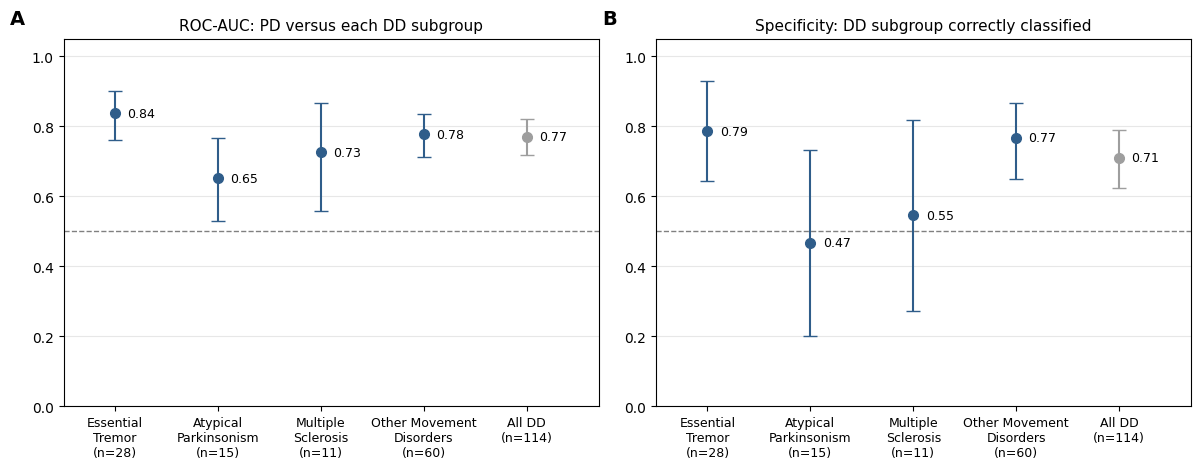

✅ saved Figure_DD_subtype_performance


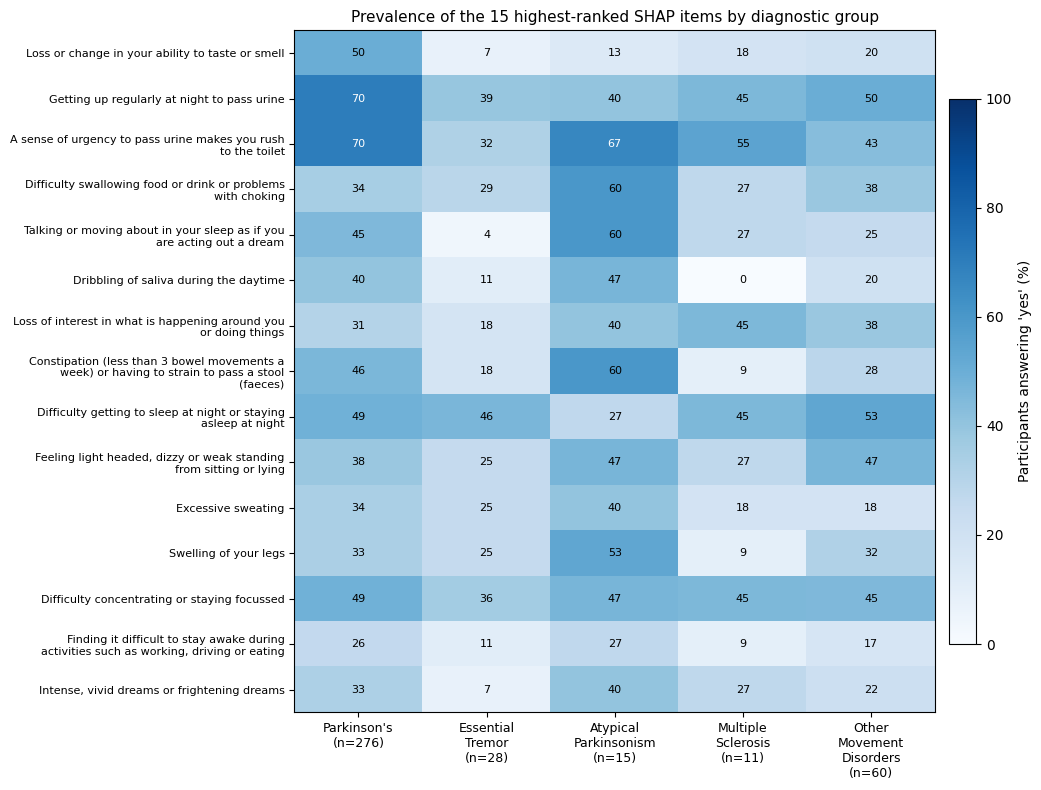

✅ saved Figure_NMS_prevalence_heatmap


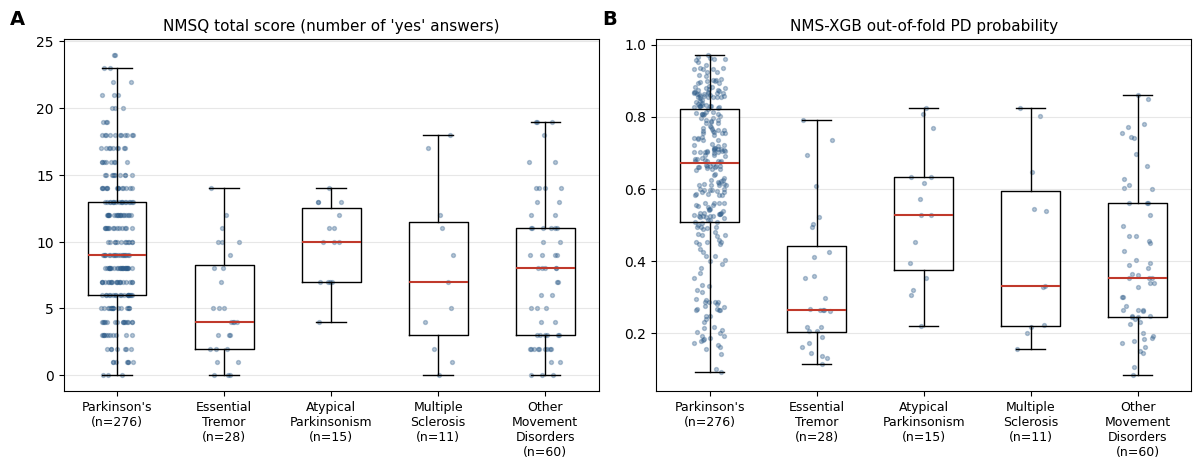

✅ saved Figure_score_and_probability_by_group

ZIP: /content/R1Q1_final_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==================================================================================================
# R1-Q1 PART 2 — CLINICAL REGROUPING OF DD FREE-TEXT DIAGNOSES + PUBLICATION FIGURES (JPG)
#
# Run AFTER the R1-Q1 cell. No model is retrained.
# Uses: revision_R1Q1_dd_characterization/analytical_cohort_with_predictions.csv
#       revision_R1Q1_dd_characterization/TableD_nms_item_prevalence_by_group.csv
#       revision_R1Q1_dd_characterization/TableC_pd_vs_each_subtype_performance.csv
# ==================================================================================================

import re
import shutil
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score

GLOBAL_SEED = 42
N_BOOTSTRAPS = 2000

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)
R1_DIR = BASE_DIR / "project_ready_data" / "revision_R1Q1_dd_characterization"
FIG_DIR = R1_DIR / "figures_final"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cohort = pd.read_csv(R1_DIR / "analytical_cohort_with_predictions.csv", dtype={"patient_id": str})
prevalence = pd.read_csv(R1_DIR / "TableD_nms_item_prevalence_by_group.csv")
performance = pd.read_csv(R1_DIR / "TableC_pd_vs_each_subtype_performance.csv")

DD_SUBTYPES = ["Essential Tremor", "Atypical Parkinsonism", "Multiple Sclerosis", "Other Movement Disorders"]
GROUP_ORDER = ["Parkinson's"] + DD_SUBTYPES

# ==================================================================================================
# 1. RULE-BASED REGROUPING OF FREE-TEXT DIAGNOSES (order of rules matters)
# ==================================================================================================
OMD_CATEGORIES = [
    "Dystonia / dystonic tremor",
    "Uncertain or early parkinsonism (SWEDD, early IPS, Lewy body, vascular)",
    "Tremor of other or unknown cause (functional, drug-induced, physiological)",
    "Cerebellar ataxia syndromes",
    "Other hyperkinetic disorders (chorea, tardive dyskinesia, RLS)",
    "Non-movement-disorder conditions",
    "Not specified",
]


def classify_omd(comment):
    text = str(comment).strip().lower()
    if text in {"", "-", "nan", "none"}:
        return OMD_CATEGORIES[6]
    if re.search(r"dyston|torticol", text):
        return OMD_CATEGORIES[0]
    if re.search(r"parkinson|\bips\b|swedd|hypokin|lewy", text):
        return OMD_CATEGORIES[1]
    if re.search(r"atax|spinocerebellar", text):
        return OMD_CATEGORIES[3]
    if re.search(r"chorea|tardive|restless", text):
        return OMD_CATEGORIES[4]
    if re.search(r"tremor", text):
        return OMD_CATEGORIES[2]
    return OMD_CATEGORIES[5]


def has_dbs(comment):
    # "THS" = Tiefe Hirnstimulation (German for deep brain stimulation)
    return bool(re.search(r"\bths\b", str(comment).lower()))


cohort["disease_comment"] = cohort["disease_comment"].fillna("-")
cohort["omd_category"] = np.where(
    cohort["group"] == "Other Movement Disorders",
    cohort["disease_comment"].apply(classify_omd),
    "",
)
cohort["deep_brain_stimulation"] = cohort["disease_comment"].apply(has_dbs)

omd = cohort[cohort["group"] == "Other Movement Disorders"]
omd_table = (
    omd["omd_category"].value_counts().reindex(OMD_CATEGORIES).fillna(0).astype(int)
    .rename_axis("category").reset_index(name="participants")
)
omd_table["percent_of_omd"] = 100 * omd_table["participants"] / omd_table["participants"].sum()
omd_table["diagnoses_included"] = omd_table["category"].map(
    omd.groupby("omd_category")["disease_comment"].apply(lambda s: "; ".join(sorted(set(s))))
)
omd_table.to_csv(R1_DIR / "TableA3_other_movement_disorders_regrouped.csv", index=False)

print("=" * 110)
print("TABLE A3 — 'OTHER MOVEMENT DISORDERS' (n=%d) REGROUPED" % len(omd))
print("=" * 110)
print(omd_table[["category", "participants", "percent_of_omd"]].to_string(index=False, float_format="%.1f"))
print("\n>>> CHECK the full mapping below; move any patient you disagree with by editing the rules.")
print(omd[["omd_category", "disease_comment"]].sort_values("omd_category").to_string(index=False))

# Deep brain stimulation (treatment status; useful for R1-Q2)
dbs = cohort.groupby("group")["deep_brain_stimulation"].agg(["sum", "count"]).reindex(GROUP_ORDER)
dbs["percent"] = 100 * dbs["sum"] / dbs["count"]
dbs.columns = ["dbs_n", "group_n", "dbs_percent"]
dbs.to_csv(R1_DIR / "TableB2_deep_brain_stimulation_by_group.csv")
print("\nDeep brain stimulation ('THS') mentioned in diagnosis text:")
print(dbs.to_string(float_format="%.1f"))

# ==================================================================================================
# 2. PD vs OMD SUB-CATEGORIES (same OOF predictions)
# ==================================================================================================
rng = np.random.default_rng(GLOBAL_SEED)
pd_rows = cohort[cohort["group"] == "Parkinson's"]


def evaluate(sub):
    data = pd.concat([pd_rows, sub])
    y = data["true_label"].astype(int).to_numpy()
    yhat = data["predicted_label"].astype(int).to_numpy()
    prob = data["probability_pd"].astype(float).to_numpy()
    spec = np.mean(yhat[y == 0] == 0)
    auc = roc_auc_score(y, prob)
    pd_idx, dd_idx = np.where(y == 1)[0], np.where(y == 0)[0]
    boot_auc, boot_spec = [], []
    for _ in range(N_BOOTSTRAPS):
        s = np.concatenate([rng.choice(pd_idx, len(pd_idx)), rng.choice(dd_idx, len(dd_idx))])
        boot_auc.append(roc_auc_score(y[s], prob[s]))
        boot_spec.append(np.mean(yhat[s][y[s] == 0] == 0))
    return auc, np.percentile(boot_auc, [2.5, 97.5]), spec, np.percentile(boot_spec, [2.5, 97.5])


omd_perf_rows = []
for category in OMD_CATEGORIES:
    sub = omd[omd["omd_category"] == category]
    if len(sub) < 5:
        omd_perf_rows.append({"category": category, "n": len(sub), "ROC-AUC [95% CI]": "n<5, not estimated",
                              "Specificity [95% CI]": f"{(sub['predicted_label'] == 0).sum()}/{len(sub)} correct"})
        continue
    auc, auc_ci, spec, spec_ci = evaluate(sub)
    omd_perf_rows.append({
        "category": category, "n": len(sub),
        "ROC-AUC [95% CI]": f"{auc:.3f} [{auc_ci[0]:.3f}–{auc_ci[1]:.3f}]",
        "Specificity [95% CI]": f"{spec:.3f} [{spec_ci[0]:.3f}–{spec_ci[1]:.3f}]",
    })
omd_perf = pd.DataFrame(omd_perf_rows)
omd_perf.to_csv(R1_DIR / "TableC2_pd_vs_omd_subcategories.csv", index=False)
print("\nPD vs 'Other Movement Disorders' sub-categories (exploratory):")
print(omd_perf.to_string(index=False))

# ==================================================================================================
# 3. PUBLICATION FIGURES (wrapped labels, 300 dpi, PNG + JPG + PDF)
# ==================================================================================================
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})


def wrap(text, width=14):
    return "\n".join(textwrap.wrap(str(text), width=width))


def save(fig, name):
    png = FIG_DIR / f"{name}.png"
    fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    Image.open(png).convert("RGB").save(FIG_DIR / f"{name}.jpg", "JPEG", quality=95, dpi=(300, 300))
    plt.show()
    plt.close(fig)
    print("✅ saved", name)


# Figure A — PD vs each DD subtype
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
labels = [
    wrap(f"{c.replace('PD vs ', '')}") + f"\n(n={n})"
    for c, n in zip(performance["comparison"], performance["n_subtype"])
]
x = np.arange(len(performance))
for ax, metric, title, letter in [
    (axes[0], "roc_auc", "ROC-AUC: PD versus each DD subgroup", "A"),
    (axes[1], "specificity_subtype", "Specificity: DD subgroup correctly classified", "B"),
]:
    values = performance[metric].to_numpy()
    err = [values - performance[metric + "_ci_lower"], performance[metric + "_ci_upper"] - values]
    colors = ["#9e9e9e" if c == "PD vs All DD" else "#2f5d8a" for c in performance["comparison"]]
    for i in range(len(values)):
        ax.errorbar(x[i], values[i], yerr=[[err[0][i]], [err[1][i]]], fmt="o", capsize=5,
                    color=colors[i], markersize=7)
        ax.text(x[i] + 0.12, values[i], f"{values[i]:.2f}", va="center", fontsize=9)
    ax.axhline(0.5, ls="--", color="grey", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_xlim(-0.5, len(values) - 0.3)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.text(-0.1, 1.04, letter, transform=ax.transAxes, fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "Figure_DD_subtype_performance")

# Figure B — prevalence heatmap (top-15 SHAP items)
heat = prevalence.head(15).copy()
heat_values = heat[[f"% {g}" for g in GROUP_ORDER]].to_numpy()
group_n = cohort["group"].value_counts()
fig, ax = plt.subplots(figsize=(10.5, 8))
image = ax.imshow(heat_values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(GROUP_ORDER)))
ax.set_xticklabels([wrap(g, 13) + f"\n(n={group_n.get(g, 0)})" for g in GROUP_ORDER], fontsize=9)
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([wrap(q, 48) for q in heat["question"]], fontsize=8)
for r in range(heat_values.shape[0]):
    for c in range(heat_values.shape[1]):
        v = heat_values[r, c]
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > 60 else "black")
cbar = plt.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Participants answering 'yes' (%)")
ax.set_title("Prevalence of the 15 highest-ranked SHAP items by diagnostic group", fontsize=11)
fig.tight_layout()
save(fig, "Figure_NMS_prevalence_heatmap")

# Figure C — NMSQ total score and predicted probability by group
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, column, title, letter in [
    (axes[0], "nmsq_total_score", "NMSQ total score (number of 'yes' answers)", "A"),
    (axes[1], "probability_pd", "NMS-XGB out-of-fold PD probability", "B"),
]:
    data = [cohort.loc[cohort["group"] == g, column].dropna() for g in GROUP_ORDER]
    ax.boxplot(data, showfliers=False, widths=0.55, medianprops={"color": "#c0392b", "lw": 1.5})
    for i, v in enumerate(data, start=1):
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(v))
        ax.scatter(np.full(len(v), i) + jitter, v, s=8, alpha=0.35, color="#2f5d8a")
    ax.set_xticks(range(1, len(GROUP_ORDER) + 1))
    ax.set_xticklabels([wrap(g, 13) + f"\n(n={len(d)})" for g, d in zip(GROUP_ORDER, data)], fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.text(-0.1, 1.04, letter, transform=ax.transAxes, fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "Figure_score_and_probability_by_group")

# ==================================================================================================
# 4. ZIP + DOWNLOAD (JPG figures + all R1-Q1 tables)
# ==================================================================================================
bundle = Path("/content/R1Q1_final_bundle")
if bundle.exists():
    shutil.rmtree(bundle)
(bundle / "figures_jpg").mkdir(parents=True)
(bundle / "figures_pdf").mkdir()
(bundle / "tables").mkdir()
for f in FIG_DIR.glob("*.jpg"):
    shutil.copy(f, bundle / "figures_jpg")
for f in FIG_DIR.glob("*.pdf"):
    shutil.copy(f, bundle / "figures_pdf")
for f in R1_DIR.glob("Table*.csv"):
    shutil.copy(f, bundle / "tables")

zip_path = shutil.make_archive("/content/R1Q1_final_bundle", "zip", bundle)
print("\nZIP:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as error:
    print("Download manually from the Files panel:", error)

## Disease duration, motor subtype, treatment and self-reported cognition (Reviewer 1, comment 2)

TABLE R2a — PD PHENOTYPE AND TREATMENT (from free-text diagnosis)
                                               characteristic      value
                                              PD participants        276
                        Motor subtype: Tremor-dominant, n (%)  52 (18.8)
                         Motor subtype: Akinetic-rigid, n (%) 114 (41.3)
                                  Motor subtype: Mixed, n (%)  80 (29.0)
                          Motor subtype: Not specified, n (%)  30 (10.9)
                                Deep brain stimulation, n (%)  40 (14.5)
Free text also mentions MSA/PSP/atypical/Lewy/vascular, n (%)   11 (4.0)

PD free-text entries flagged as mentioning another parkinsonian diagnosis (check manually):
patient_id                                               disease_comment
       020                                                Starting MSA-P
       026          Atypical Parkinsonism with orthostatic dysregulation
       059                            

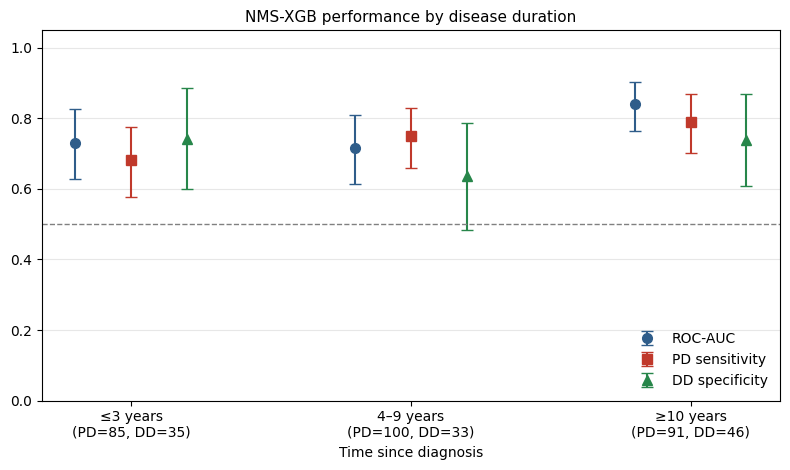


ZIP: /content/R1Q2_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ R1-Q2 ANALYSIS FINISHED (no model was retrained).


In [ ]:
# ==================================================================================================
# REVISION — REVIEWER 1, COMMENT 2: COHORT DESCRIPTION (STAGE, PHENOTYPE, COGNITION, TREATMENT)
#
# No model is retrained. Uses the R1-Q1 output:
#   revision_R1Q1_dd_characterization/analytical_cohort_with_predictions.csv
#   model_j_nms_question_mapping.csv (question text)
#
# What PADS provides / does not provide (Varghese et al., npj Parkinson's Dis 2024):
#   available     : age, age at diagnosis -> disease duration, free-text diagnosis
#                   (PD motor subtype, deep brain stimulation), 30 self-reported NMS items
#   NOT available : UPDRS, Hoehn & Yahr, MoCA/MMSE, medication (not in the public release)
#
# Outputs (revision_R1Q2_cohort/):
#   Table_R2a_pd_phenotype.csv            PD motor subtype, DBS, label notes
#   Table_R2b_self_reported_cognition.csv memory / concentration / hallucination items by group
#   Table_R2c_performance_by_duration.csv AUC, PD sensitivity, DD specificity by disease-duration stratum
#   Table_R2d_pd_sensitivity_by_phenotype.csv  PD sensitivity by motor subtype and DBS
#   Figure_performance_by_duration.(png/jpg/pdf)
# ==================================================================================================

import re
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.metrics import roc_auc_score

GLOBAL_SEED = 42
N_BOOTSTRAPS = 2000

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)
PROJECT_DIR = BASE_DIR / "project_ready_data"
R1_DIR = PROJECT_DIR / "revision_R1Q1_dd_characterization"
OUT_DIR = PROJECT_DIR / "revision_R1Q2_cohort"
OUT_DIR.mkdir(parents=True, exist_ok=True)

GROUP_ORDER = ["Parkinson's", "Essential Tremor", "Atypical Parkinsonism",
               "Multiple Sclerosis", "Other Movement Disorders"]

cohort = pd.read_csv(R1_DIR / "analytical_cohort_with_predictions.csv", dtype={"patient_id": str})
cohort["disease_comment"] = cohort["disease_comment"].fillna("-").astype(str)
cohort["is_pd"] = cohort["group"] == "Parkinson's"
rng = np.random.default_rng(GLOBAL_SEED)


def pct(mask):
    mask = pd.Series(mask).dropna()
    return f"{int(mask.sum())} ({100 * mask.mean():.1f})" if len(mask) else "–"


def fmt_p(p):
    return "–" if not np.isfinite(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")


# ==================================================================================================
# 1. PD PHENOTYPE AND TREATMENT FROM FREE-TEXT DIAGNOSIS
# ==================================================================================================
def pd_subtype(text):
    t = text.lower()
    if re.search(r"tremor\s*-?\s*dominant|tremordominant", t):
        return "Tremor-dominant"
    if re.search(r"akinetic|rigid", t):
        return "Akinetic-rigid"
    if re.search(r"mixed|equivalen", t):
        return "Mixed"
    return "Not specified"


cohort["dbs"] = cohort["disease_comment"].str.contains(r"\bTHS\b", case=False, regex=True)
pd_rows = cohort[cohort["is_pd"]].copy()
pd_rows["motor_subtype"] = pd_rows["disease_comment"].apply(pd_subtype)
# PD-labelled participants whose free text mentions another parkinsonian diagnosis
pd_rows["text_mentions_atypical"] = pd_rows["disease_comment"].str.contains(
    r"MSA|PSP|multiple system|supranuclear|atypical|lewy|vascular", case=False, regex=True)
cohort.loc[pd_rows.index, "motor_subtype"] = pd_rows["motor_subtype"]
cohort["text_mentions_atypical"] = False
cohort.loc[pd_rows.index, "text_mentions_atypical"] = pd_rows["text_mentions_atypical"]

phenotype_rows = [{"characteristic": "PD participants", "value": str(len(pd_rows))}]
for subtype in ["Tremor-dominant", "Akinetic-rigid", "Mixed", "Not specified"]:
    phenotype_rows.append({"characteristic": f"Motor subtype: {subtype}, n (%)",
                           "value": pct(pd_rows["motor_subtype"] == subtype)})
phenotype_rows.append({"characteristic": "Deep brain stimulation, n (%)", "value": pct(pd_rows["dbs"])})
phenotype_rows.append({"characteristic": "Free text also mentions MSA/PSP/atypical/Lewy/vascular, n (%)",
                       "value": pct(pd_rows["text_mentions_atypical"])})
phenotype = pd.DataFrame(phenotype_rows)
phenotype.to_csv(OUT_DIR / "Table_R2a_pd_phenotype.csv", index=False)

print("=" * 110)
print("TABLE R2a — PD PHENOTYPE AND TREATMENT (from free-text diagnosis)")
print("=" * 110)
print(phenotype.to_string(index=False))
print("\nPD free-text entries flagged as mentioning another parkinsonian diagnosis (check manually):")
print(pd_rows.loc[pd_rows["text_mentions_atypical"], ["patient_id", "disease_comment"]].to_string(index=False))

# ==================================================================================================
# 2. SELF-REPORTED COGNITIVE / NEUROPSYCHIATRIC SYMPTOMS (proxy only — not cognitive testing)
# ==================================================================================================
question_text = {}
mapping_files = sorted(PROJECT_DIR.rglob("model_j_nms_question_mapping.csv"))
if mapping_files:
    mapping = pd.read_csv(mapping_files[0])
    question_text = mapping.drop_duplicates("feature").set_index("feature")["question_text"].to_dict()

keyword_items = {
    "Memory complaints": r"forget|remember|memory",
    "Difficulty concentrating": r"concentrat|focus",
    "Hallucinations": r"seeing or hearing|hallucinat",
    "Delusions": r"believ|delusion|not true",
    "Low mood": r"sad|low|blue",
    "Anxiety": r"anxious|frightened|panick",
}
cognition_rows = []
for label, pattern in keyword_items.items():
    matches = [f for f, q in question_text.items() if re.search(pattern, str(q), re.I)]
    if not matches:
        print(f"Item not found for '{label}' — skipped.")
        continue
    item = matches[0]
    row = {"symptom": label, "item": item, "question": question_text[item]}
    for g in GROUP_ORDER:
        row[g] = pct(cohort.loc[cohort["group"] == g, item])
    table = pd.crosstab(cohort["group"], cohort[item]).reindex(GROUP_ORDER)
    row["p (5 groups)"] = fmt_p(stats.chi2_contingency(table).pvalue) if table.shape[1] == 2 else "–"
    cognition_rows.append(row)
cognition = pd.DataFrame(cognition_rows)
cognition.to_csv(OUT_DIR / "Table_R2b_self_reported_cognition.csv", index=False)
print("\n" + "=" * 110)
print("TABLE R2b — SELF-REPORTED COGNITIVE AND NEUROPSYCHIATRIC SYMPTOMS, n (%)")
print("=" * 110)
print(cognition.drop(columns=["question"]).to_string(index=False))

# ==================================================================================================
# 3. DOES PERFORMANCE DEPEND ON DISEASE DURATION? (same out-of-fold predictions)
# ==================================================================================================
bins = [-np.inf, 3, 9, np.inf]
labels = ["≤3 years", "4–9 years", "≥10 years"]
cohort["duration_stratum"] = pd.cut(cohort["disease_duration_years"], bins=bins, labels=labels)


def boot_ci(y, yhat, prob):
    pd_idx, dd_idx = np.where(y == 1)[0], np.where(y == 0)[0]
    aucs, senss, specs = [], [], []
    for _ in range(N_BOOTSTRAPS):
        s = np.concatenate([rng.choice(pd_idx, len(pd_idx)), rng.choice(dd_idx, len(dd_idx))])
        aucs.append(roc_auc_score(y[s], prob[s]))
        senss.append(np.mean(yhat[s][y[s] == 1] == 1))
        specs.append(np.mean(yhat[s][y[s] == 0] == 0))
    return [np.percentile(v, [2.5, 97.5]) for v in (aucs, senss, specs)]


duration_rows = []
for stratum in labels:
    d = cohort[cohort["duration_stratum"] == stratum]
    y = d["true_label"].astype(int).to_numpy()
    yhat = d["predicted_label"].astype(int).to_numpy()
    prob = d["probability_pd"].astype(float).to_numpy()
    if (y == 1).sum() < 2 or (y == 0).sum() < 2:
        print(f"Stratum {stratum}: too few PD or DD participants — skipped.")
        continue
    auc = roc_auc_score(y, prob)
    sens = np.mean(yhat[y == 1] == 1)
    spec = np.mean(yhat[y == 0] == 0)
    auc_ci, sens_ci, spec_ci = boot_ci(y, yhat, prob)
    duration_rows.append({
        "duration": stratum, "n_pd": int((y == 1).sum()), "n_dd": int((y == 0).sum()),
        "roc_auc": auc, "auc_lo": auc_ci[0], "auc_hi": auc_ci[1],
        "sensitivity_pd": sens, "sens_lo": sens_ci[0], "sens_hi": sens_ci[1],
        "specificity_dd": spec, "spec_lo": spec_ci[0], "spec_hi": spec_ci[1],
    })
duration = pd.DataFrame(duration_rows)
duration.to_csv(OUT_DIR / "Table_R2c_performance_by_duration.csv", index=False)

print("\n" + "=" * 110)
print("TABLE R2c — PERFORMANCE BY DISEASE-DURATION STRATUM")
print("=" * 110)
for r in duration.itertuples():
    print(f"{r.duration:10s} PD={r.n_pd:3d} DD={r.n_dd:3d} | "
          f"AUC {r.roc_auc:.3f} [{r.auc_lo:.3f}–{r.auc_hi:.3f}] | "
          f"Sens {r.sensitivity_pd:.3f} [{r.sens_lo:.3f}–{r.sens_hi:.3f}] | "
          f"Spec {r.specificity_dd:.3f} [{r.spec_lo:.3f}–{r.spec_hi:.3f}]")

# Trend tests
for name, mask in [("PD", cohort["is_pd"]), ("DD", ~cohort["is_pd"])]:
    sub = cohort[mask].dropna(subset=["disease_duration_years"])
    rho, p = stats.spearmanr(sub["disease_duration_years"], sub["probability_pd"])
    print(f"{name}: Spearman rho (duration vs predicted PD probability) = {rho:.3f}, p = {fmt_p(p)}")
sub = cohort[cohort["is_pd"]]
correct = (sub["predicted_label"] == 1).astype(int)
p_trend = stats.chi2_contingency(pd.crosstab(sub["duration_stratum"], correct)).pvalue
print(f"PD sensitivity across duration strata: chi-square p = {fmt_p(p_trend)}")
rho_nmsq, p_nmsq = stats.spearmanr(sub["disease_duration_years"], sub["nmsq_total_score"], nan_policy="omit")
print(f"PD: Spearman rho (duration vs NMSQ total score) = {rho_nmsq:.3f}, p = {fmt_p(p_nmsq)}")

# ==================================================================================================
# 4. PD SENSITIVITY BY MOTOR SUBTYPE AND DBS
# ==================================================================================================
sens_rows = []
pd_eval = cohort[cohort["is_pd"]].copy()
for variable, levels in [("motor_subtype", ["Tremor-dominant", "Akinetic-rigid", "Mixed", "Not specified"]),
                         ("dbs", [False, True]), ("text_mentions_atypical", [False, True])]:
    for level in levels:
        s = pd_eval[pd_eval[variable] == level]
        if len(s) == 0:
            continue
        sens_rows.append({"variable": variable, "level": str(level), "n": len(s),
                          "pd_sensitivity": f'{(s["predicted_label"] == 1).mean():.3f}',
                          "median_probability_pd": f'{s["probability_pd"].median():.3f}'})
    table = pd.crosstab(pd_eval[variable], pd_eval["predicted_label"] == 1)
    if table.shape == (2, 2):
        p = stats.fisher_exact(table.to_numpy()).pvalue
    elif table.shape[0] > 1 and table.shape[1] == 2:
        p = stats.chi2_contingency(table).pvalue
    else:
        p = np.nan
    sens_rows.append({"variable": variable, "level": "p-value", "n": "", "pd_sensitivity": fmt_p(p),
                      "median_probability_pd": ""})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(OUT_DIR / "Table_R2d_pd_sensitivity_by_phenotype.csv", index=False)
print("\n" + "=" * 110)
print("TABLE R2d — PD SENSITIVITY BY MOTOR SUBTYPE, DBS AND LABEL NOTE")
print("=" * 110)
print(sensitivity.to_string(index=False))

# Sensitivity analysis: exclude PD participants whose text mentions another parkinsonian diagnosis
clean = cohort[~cohort["text_mentions_atypical"].astype(bool)]
y, yhat, prob = clean["true_label"].to_numpy(), clean["predicted_label"].to_numpy(), clean["probability_pd"].to_numpy()
ba = 0.5 * (np.mean(yhat[y == 1] == 1) + np.mean(yhat[y == 0] == 0))
print(f"\nExcluding {cohort['text_mentions_atypical'].sum()} PD participants with atypical mentions: "
      f"n={len(clean)}, BA={ba:.4f}, ROC-AUC={roc_auc_score(y, prob):.4f}")

# ==================================================================================================
# 5. FIGURE
# ==================================================================================================
fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(duration))
offsets = {"roc_auc": -0.2, "sensitivity_pd": 0.0, "specificity_dd": 0.2}
names = {"roc_auc": "ROC-AUC", "sensitivity_pd": "PD sensitivity", "specificity_dd": "DD specificity"}
ci = {"roc_auc": ("auc_lo", "auc_hi"), "sensitivity_pd": ("sens_lo", "sens_hi"),
      "specificity_dd": ("spec_lo", "spec_hi")}
markers = {"roc_auc": "o", "sensitivity_pd": "s", "specificity_dd": "^"}
colors = {"roc_auc": "#2f5d8a", "sensitivity_pd": "#c0392b", "specificity_dd": "#27864a"}
for metric, off in offsets.items():
    v = duration[metric].to_numpy()
    lo, hi = duration[ci[metric][0]].to_numpy(), duration[ci[metric][1]].to_numpy()
    ax.errorbar(x + off, v, yerr=[v - lo, hi - v], fmt=markers[metric], capsize=4,
                color=colors[metric], label=names[metric], markersize=7)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.duration}\n(PD={r.n_pd}, DD={r.n_dd})" for r in duration.itertuples()])
ax.set_xlabel("Time since diagnosis")
ax.set_ylim(0, 1.05)
ax.axhline(0.5, ls="--", color="grey", lw=1)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right", frameon=False)
ax.set_title("NMS-XGB performance by disease duration", fontsize=11)
fig.tight_layout()
png = OUT_DIR / "Figure_performance_by_duration.png"
fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT_DIR / "Figure_performance_by_duration.pdf", bbox_inches="tight", facecolor="white")
Image.open(png).convert("RGB").save(OUT_DIR / "Figure_performance_by_duration.jpg", "JPEG", quality=95, dpi=(300, 300))
plt.show()
plt.close(fig)

# ==================================================================================================
# 6. ZIP + DOWNLOAD
# ==================================================================================================
zip_path = shutil.make_archive("/content/R1Q2_bundle", "zip", OUT_DIR)
print("\nZIP:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as error:
    print("Download manually from the Files panel:", error)
print("✅ R1-Q2 ANALYSIS FINISHED (no model was retrained).")

## Comparison with the questionnaire total score and routine clinical features (Reviewer 1, comment 6)

R1-Q6 — COMPARISON WITH ROUTINE CLINICAL FEATURES AND THE NMSQ TOTAL SCORE
Patients: 390 (PD=276, DD=114) | outer folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
✅ Clinical features done
✅ Clinical + NMSQ total score done
✅ Clinical + 30 NMS items (logistic) done

TABLE R6a — POOLED OUT-OF-FOLD PERFORMANCE [95% bootstrap CI]
                             model             roc_auc   balanced_accuracy         sensitivity         specificity
                  NMSQ total score 0.634 [0.573–0.695] 0.589 [0.543–0.642] 0.819 [0.775–0.862] 0.360 [0.276–0.455]
                 Clinical features 0.627 [0.564–0.687] 0.600 [0.547–0.653] 0.699 [0.647–0.754] 0.500 [0.408–0.594]
       Clinical + NMSQ total score 0.668 [0.608–0.723] 0.631 [0.580–0.682] 0.649 [0.590–0.708] 0.614 [0.523–0.700]
Clinical + 30 NMS items (logistic) 0.763 [0.707–0.813] 0.671 [0.619–0.722] 0.685 [0.628–0.739] 0.658 [0.569–0.745]
                NMS-XGB (proposed) 0.770 [0.720–0.820] 0.727 [0.678–0.776

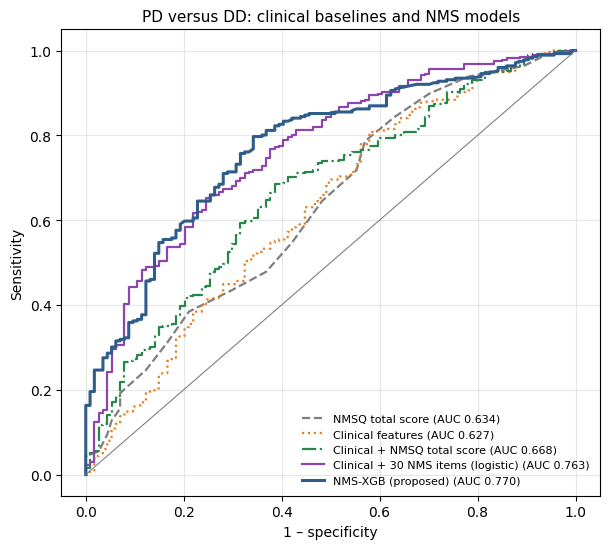


ZIP: /content/R1Q6_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ R1-Q6 ANALYSIS FINISHED (NMS-XGB not retrained).


In [ ]:
# ==================================================================================================
# REVISION — REVIEWER 1, COMMENT 6 (+ supports R1-Q3 and R2-2.1)
# DOES THE NMS MODEL ADD INFORMATION BEYOND ROUTINE CLINICAL FEATURES AND THE NMSQ TOTAL SCORE?
#
# Models (all on the SAME fixed five patient-level outer folds; nothing tuned on outer-test patients):
#   M1  NMSQ total score            number of "yes" answers (standard scale score); cutoff chosen on
#                                   outer-training patients only
#   M2  Clinical                    logistic regression: age, sex, family history, alcohol effect on tremor
#   M3  Clinical + NMSQ total       logistic regression
#   M4  Clinical + 30 NMS items     logistic regression (L2)
#   M5  NMS-XGB (proposed)          existing Model-J out-of-fold predictions (not retrained)
#
# Logistic models: standardisation + C tuned by inner stratified 5-fold CV on outer-training patients,
# classification threshold = the one maximising balanced accuracy on inner out-of-fold predictions.
#
# Outputs (project_ready_data/revision_R1Q6_clinical_comparison/):
#   Table_R6a_model_performance.csv     AUC, BA, sensitivity, specificity with 95% CI
#   Table_R6b_paired_differences.csv    paired bootstrap ΔAUC and ΔBA for the key comparisons
#   R6_patient_predictions.csv
#   Figure_clinical_comparison_roc.(png/jpg/pdf)
# ==================================================================================================

import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

GLOBAL_SEED = 42
N_BOOTSTRAPS = 2000
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)
PROJECT_DIR = BASE_DIR / "project_ready_data"
R1_DIR = PROJECT_DIR / "revision_R1Q1_dd_characterization"
OUT_DIR = PROJECT_DIR / "revision_R1Q6_clinical_comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def normalize_ids(series):
    return (pd.Series(series).astype(str).str.strip()
            .str.replace(r"\.0$", "", regex=True).str.extract(r"(\d+)", expand=False).str.zfill(3))


# ==================================================================================================
# 1. DATA
# ==================================================================================================
cohort = pd.read_csv(R1_DIR / "analytical_cohort_with_predictions.csv", dtype={"patient_id": str})
cohort["patient_id"] = normalize_ids(cohort["patient_id"])

# Outer folds exactly as used by Model J
prediction_file = sorted(PROJECT_DIR.rglob("model_j_patient_predictions.csv"))[0]
mj = pd.read_csv(prediction_file)
mj = mj[mj["configuration"].astype(str).str.lower() == "nms_items_only"].copy()
mj["patient_id"] = normalize_ids(mj["patient_id"])
cohort = cohort.merge(mj[["patient_id", "outer_fold"]], on="patient_id", how="left", validate="one_to_one")
if cohort["outer_fold"].isna().any():
    raise RuntimeError("Some patients have no outer-fold assignment.")

NMS_COLUMNS = [f"nms_{i:02d}" for i in range(1, 31)]
cohort["nmsq_total"] = cohort[NMS_COLUMNS].sum(axis=1)

# Routine clinical history features
cohort["age_num"] = pd.to_numeric(cohort["age"], errors="coerce")
cohort["female"] = cohort["gender"].astype(str).str.lower().str.startswith("f").astype(float)
cohort["family_history"] = cohort["appearance_in_kinship"].astype(str).str.lower().isin(["true", "1", "yes"]).astype(float)
alcohol = cohort["effect_of_alcohol_on_tremor"].astype(str).str.strip().str.lower()
cohort["alcohol_improves"] = (alcohol == "improvement").astype(float)
cohort["alcohol_worsens"] = (alcohol == "worsening").astype(float)
cohort["alcohol_no_effect"] = (alcohol == "no effect").astype(float)
# reference category = "unknown"

CLINICAL = ["age_num", "female", "family_history", "alcohol_improves", "alcohol_worsens", "alcohol_no_effect"]
if cohort[CLINICAL].isna().any().any():
    cohort[CLINICAL] = cohort[CLINICAL].fillna(cohort[CLINICAL].median())  # age only; median is negligible here

y_all = cohort["true_label"].astype(int).to_numpy()
folds = cohort["outer_fold"].astype(int).to_numpy()
print("=" * 110)
print("R1-Q6 — COMPARISON WITH ROUTINE CLINICAL FEATURES AND THE NMSQ TOTAL SCORE")
print("=" * 110)
print(f"Patients: {len(cohort)} (PD={y_all.sum()}, DD={(y_all == 0).sum()}) | outer folds: {sorted(set(folds))}")


# ==================================================================================================
# 2. HELPERS
# ==================================================================================================
def best_threshold(y, p):
    candidates = np.unique(np.round(p, 4))
    best_t, best_ba = 0.5, -1
    for t in candidates:
        pred = (p >= t).astype(int)
        ba = 0.5 * (np.mean(pred[y == 1] == 1) + np.mean(pred[y == 0] == 0))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t


def fit_logistic_fold(X_train, y_train, X_test, seed):
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    best = (None, -np.inf, None)
    for C in C_GRID:
        oof = np.zeros(len(y_train))
        for tr, va in inner.split(X_train, y_train):
            model = make_pipeline(StandardScaler(), LogisticRegression(
                C=C, class_weight="balanced", max_iter=5000))
            model.fit(X_train[tr], y_train[tr])
            oof[va] = model.predict_proba(X_train[va])[:, 1]
        auc = roc_auc_score(y_train, oof)
        if auc > best[1]:
            best = (C, auc, oof)
    C, _, oof = best
    threshold = best_threshold(y_train, oof)
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))
    model.fit(X_train, y_train)
    return model.predict_proba(X_test)[:, 1], threshold, C


probabilities, predictions, chosen = {}, {}, []

# M1 — NMSQ total score (no fitting; cutoff from outer-training patients)
p = cohort["nmsq_total"].to_numpy(float)
pred = np.zeros(len(cohort), int)
for f in sorted(set(folds)):
    train, test = folds != f, folds == f
    t = best_threshold(y_all[train], p[train])
    pred[test] = (p[test] >= t).astype(int)
    chosen.append({"model": "NMSQ total score", "fold": f, "C": "", "threshold": t})
probabilities["NMSQ total score"], predictions["NMSQ total score"] = p, pred

# M2–M4 — logistic models
feature_sets = {
    "Clinical features": CLINICAL,
    "Clinical + NMSQ total score": CLINICAL + ["nmsq_total"],
    "Clinical + 30 NMS items (logistic)": CLINICAL + NMS_COLUMNS,
}
for name, columns in feature_sets.items():
    X = cohort[columns].to_numpy(float)
    prob = np.zeros(len(cohort))
    pred = np.zeros(len(cohort), int)
    for f in sorted(set(folds)):
        train, test = folds != f, folds == f
        prob_test, t, C = fit_logistic_fold(X[train], y_all[train], X[test], GLOBAL_SEED + int(f))
        prob[test] = prob_test
        pred[test] = (prob_test >= t).astype(int)
        chosen.append({"model": name, "fold": f, "C": C, "threshold": round(float(t), 4)})
    probabilities[name], predictions[name] = prob, pred
    print(f"✅ {name} done")

# M5 — proposed NMS-XGB (existing untouched OOF predictions)
probabilities["NMS-XGB (proposed)"] = cohort["probability_pd"].to_numpy(float)
predictions["NMS-XGB (proposed)"] = cohort["predicted_label"].astype(int).to_numpy()

pd.DataFrame(chosen).to_csv(OUT_DIR / "R6_selected_parameters_by_fold.csv", index=False)
out = cohort[["patient_id", "outer_fold", "true_label", "group"]].copy()
for name in probabilities:
    out[f"prob__{name}"] = probabilities[name]
    out[f"pred__{name}"] = predictions[name]
out.to_csv(OUT_DIR / "R6_patient_predictions.csv", index=False)


# ==================================================================================================
# 3. METRICS + BOOTSTRAP
# ==================================================================================================
def metrics(y, pred, prob):
    sens = np.mean(pred[y == 1] == 1)
    spec = np.mean(pred[y == 0] == 0)
    return {"roc_auc": roc_auc_score(y, prob), "balanced_accuracy": 0.5 * (sens + spec),
            "sensitivity": sens, "specificity": spec}


MODEL_ORDER = list(probabilities.keys())
point = {m: metrics(y_all, predictions[m], probabilities[m]) for m in MODEL_ORDER}

rng = np.random.default_rng(GLOBAL_SEED)
boot = {m: [] for m in MODEL_ORDER}
for _ in range(N_BOOTSTRAPS):
    idx = rng.integers(0, len(y_all), len(y_all))
    if len(np.unique(y_all[idx])) < 2:
        continue
    for m in MODEL_ORDER:
        boot[m].append(metrics(y_all[idx], predictions[m][idx], probabilities[m][idx]))
boot = {m: pd.DataFrame(v) for m, v in boot.items()}

rows = []
for m in MODEL_ORDER:
    row = {"model": m}
    for k in ["roc_auc", "balanced_accuracy", "sensitivity", "specificity"]:
        lo, hi = np.percentile(boot[m][k], [2.5, 97.5])
        row[k] = f"{point[m][k]:.3f} [{lo:.3f}–{hi:.3f}]"
    rows.append(row)
table_a = pd.DataFrame(rows)
table_a.to_csv(OUT_DIR / "Table_R6a_model_performance.csv", index=False)
print("\n" + "=" * 110)
print("TABLE R6a — POOLED OUT-OF-FOLD PERFORMANCE [95% bootstrap CI]")
print("=" * 110)
print(table_a.to_string(index=False))

comparisons = [
    ("NMS-XGB (proposed)", "NMSQ total score", "Item-level model vs standard scale score"),
    ("NMS-XGB (proposed)", "Clinical features", "NMS model vs routine clinical features"),
    ("NMS-XGB (proposed)", "Clinical + NMSQ total score", "NMS model vs clinical + scale score"),
    ("Clinical + NMSQ total score", "Clinical features", "Added value of NMSQ total score over clinical"),
    ("Clinical + 30 NMS items (logistic)", "Clinical features", "Added value of 30 items over clinical"),
    ("Clinical + 30 NMS items (logistic)", "Clinical + NMSQ total score", "Item-level vs total score (both with clinical)"),
]
diff_rows = []
for a, b, label in comparisons:
    row = {"comparison": f"{a} minus {b}", "question": label}
    for k in ["roc_auc", "balanced_accuracy"]:
        d = boot[a][k].to_numpy() - boot[b][k].to_numpy()
        obs = point[a][k] - point[b][k]
        lo, hi = np.percentile(d, [2.5, 97.5])
        row[f"delta_{k}"] = f"{obs:+.3f} [{lo:+.3f} to {hi:+.3f}]"
        row[f"P(delta>0)_{k}"] = f"{np.mean(d > 0):.3f}"
    diff_rows.append(row)
table_b = pd.DataFrame(diff_rows)
table_b.to_csv(OUT_DIR / "Table_R6b_paired_differences.csv", index=False)
print("\n" + "=" * 110)
print("TABLE R6b — PAIRED BOOTSTRAP DIFFERENCES (first model minus second)")
print("=" * 110)
for r in table_b.itertuples():
    print(f"\n{r.question}\n  {r.comparison}\n  ΔAUC {r.delta_roc_auc}  |  ΔBA {r.delta_balanced_accuracy}")

# Clinical-model coefficients on the full cohort (descriptive only)
full = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
full.fit(cohort[CLINICAL + ["nmsq_total"]].to_numpy(float), y_all)
coef = pd.Series(full[-1].coef_[0], index=CLINICAL + ["nmsq_total"]).round(3)
print("\nStandardised coefficients, clinical + NMSQ total model fitted on all patients (descriptive only):")
print(coef.to_string())

# ==================================================================================================
# 4. ROC FIGURE
# ==================================================================================================
styles = {
    "NMSQ total score": ("#7f7f7f", "--"),
    "Clinical features": ("#e67e22", ":"),
    "Clinical + NMSQ total score": ("#27864a", "-."),
    "Clinical + 30 NMS items (logistic)": ("#8e44ad", "-"),
    "NMS-XGB (proposed)": ("#2f5d8a", "-"),
}
fig, ax = plt.subplots(figsize=(6.2, 5.6))
for m in MODEL_ORDER:
    fpr, tpr, _ = roc_curve(y_all, probabilities[m])
    color, ls = styles[m]
    ax.plot(fpr, tpr, ls, color=color, lw=2.2 if "proposed" in m else 1.6,
            label=f"{m} (AUC {point[m]['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set_xlabel("1 – specificity")
ax.set_ylabel("Sensitivity")
ax.set_title("PD versus DD: clinical baselines and NMS models", fontsize=11)
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
png = OUT_DIR / "Figure_clinical_comparison_roc.png"
fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT_DIR / "Figure_clinical_comparison_roc.pdf", bbox_inches="tight", facecolor="white")
Image.open(png).convert("RGB").save(OUT_DIR / "Figure_clinical_comparison_roc.jpg", "JPEG", quality=95, dpi=(300, 300))
plt.show()
plt.close(fig)

zip_path = shutil.make_archive("/content/R1Q6_bundle", "zip", OUT_DIR)
print("\nZIP:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as error:
    print("Download manually from the Files panel:", error)
print("✅ R1-Q6 ANALYSIS FINISHED (NMS-XGB not retrained).")

## Participant list with outer-fold assignment

In [ ]:
# Export the participant list with diagnostic group and outer fold (shared as a supplementary file)
import json
import pandas as pd
from pathlib import Path
BASE = Path("/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0")
mj = pd.read_csv(next(BASE.rglob("model_j_patient_predictions.csv")), dtype={"patient_id": str})
mj = mj[mj["configuration"] == "nms_items_only"].copy()
mj["patient_id"] = mj["patient_id"].str.replace(r"\.0$", "", regex=True).str.zfill(3)
rows = []
for f in BASE.rglob("patient_*.json"):
    rec = json.loads(f.read_text(encoding="utf-8"))
    if isinstance(rec, dict) and "condition" in rec:
        rows.append({"patient_id": str(rec.get("id", f.stem)).zfill(3), "diagnostic_group": rec["condition"]})
groups = pd.DataFrame(rows).drop_duplicates("patient_id")
s1 = (mj[["patient_id", "outer_fold"]].merge(groups, on="patient_id", how="left", validate="one_to_one")
      .rename(columns={"patient_id": "PADS_participant_id"}).sort_values("PADS_participant_id"))
assert len(s1) == 390
s1.to_csv("/content/cohort_and_folds.csv", index=False)
print(s1["diagnostic_group"].value_counts())